In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('../data/DataCoSupplyChainDataset.csv', encoding='latin1', low_memory=False)

In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,02-03-2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
df.shape

(180519, 53)

In [6]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [8]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [9]:
required_columns = [
    'Order Id',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Delivery Status',
    'Late_delivery_risk',
    'Shipping Mode',
    'order date (DateOrders)',
    'shipping date (DateOrders)',
    'Order Region',
    'Order State',
    'Order Country',
    'Customer Segment',
    'Order Item Quantity',
    'Sales'
]

df = df[required_columns].copy()

In [10]:
df.head()

,Order Id,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Shipping Mode,order date (DateOrders),shipping date (DateOrders),Order Region,Order State,Order Country,Customer Segment,Order Item Quantity,Sales
0,77202,3,4,Advance shipping,0,Standard Class,1/31/2018 22:56,02-03-2018 22:56,Southeast Asia,Java Occidental,Indonesia,Consumer,1,327.75
1,75939,5,4,Late delivery,1,Standard Class,1/13/2018 12:27,1/18/2018 12:27,South Asia,Rajastán,India,Consumer,1,327.75
2,75938,4,4,Shipping on time,0,Standard Class,1/13/2018 12:06,1/17/2018 12:06,South Asia,Rajastán,India,Consumer,1,327.75
3,75937,3,4,Advance shipping,0,Standard Class,1/13/2018 11:45,1/16/2018 11:45,Oceania,Queensland,Australia,Home Office,1,327.75
4,75936,2,4,Advance shipping,0,Standard Class,1/13/2018 11:24,1/15/2018 11:24,Oceania,Queensland,Australia,Corporate,1,327.75


In [11]:
df.isnull().sum()

Order Id                         0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Delivery Status                  0
Late_delivery_risk               0
Shipping Mode                    0
order date (DateOrders)          0
shipping date (DateOrders)       0
Order Region                     0
Order State                      0
Order Country                    0
Customer Segment                 0
Order Item Quantity              0
Sales                            0
dtype: int64

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

Order Id                         0.0
Days for shipping (real)         0.0
Days for shipment (scheduled)    0.0
Delivery Status                  0.0
Late_delivery_risk               0.0
Shipping Mode                    0.0
order date (DateOrders)          0.0
shipping date (DateOrders)       0.0
Order Region                     0.0
Order State                      0.0
Order Country                    0.0
Customer Segment                 0.0
Order Item Quantity              0.0
Sales                            0.0
dtype: float64

In [13]:
df.duplicated().sum()

np.int64(11529)

In [14]:
df = df.drop_duplicates()

In [15]:
df = df.drop_duplicates()

In [16]:
df = df.rename(columns={
    'Order Id': 'Order_ID',
    'Days for shipping (real)': 'Actual_Shipping_Days',
    'Days for shipment (scheduled)': 'Scheduled_Shipping_Days',
    'Delivery Status': 'Delivery_Status',
    'Late_delivery_risk': 'Late_Delivery_Risk',
    'Shipping Mode': 'Shipping_Mode',
    'order date (DateOrders)': 'Order_Date',
    'shipping date (DateOrders)': 'Shipping_Date',
    'Order Region': 'Order_Region',
    'Order State': 'Order_State',
    'Order Country': 'Order_Country',
    'Customer Segment': 'Customer_Segment',
    'Order Item Quantity': 'Order_Quantity',
    'Sales': 'Sales'
})

In [17]:
df.columns

Index(['Order_ID', 'Actual_Shipping_Days', 'Scheduled_Shipping_Days',
       'Delivery_Status', 'Late_Delivery_Risk', 'Shipping_Mode', 'Order_Date',
       'Shipping_Date', 'Order_Region', 'Order_State', 'Order_Country',
       'Customer_Segment', 'Order_Quantity', 'Sales'],
      dtype='str')

In [18]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce', format='mixed')

df['Shipping_Date'] = pd.to_datetime(df['Shipping_Date'], errors='coerce', format='mixed')

In [19]:
df[['Order_Date', 'Shipping_Date']].head()

,Order_Date,Shipping_Date
0,2018-01-31 22:56:00,2018-02-03 22:56:00
1,2018-01-13 12:27:00,2018-01-18 12:27:00
2,2018-01-13 12:06:00,2018-01-17 12:06:00
3,2018-01-13 11:45:00,2018-01-16 11:45:00
4,2018-01-13 11:24:00,2018-01-15 11:24:00


In [20]:
df[['Order_Date', 'Shipping_Date']].dtypes

Order_Date       datetime64[us]
Shipping_Date    datetime64[us]
dtype: object

In [21]:
df.isnull().sum()

Order_ID                   0
Actual_Shipping_Days       0
Scheduled_Shipping_Days    0
Delivery_Status            0
Late_Delivery_Risk         0
Shipping_Mode              0
Order_Date                 0
Shipping_Date              0
Order_Region               0
Order_State                0
Order_Country              0
Customer_Segment           0
Order_Quantity             0
Sales                      0
dtype: int64

In [22]:
df = df.dropna(subset=['Order_Date'])

In [23]:
df[df['Actual_Shipping_Days'] < 0]

,Order_ID,Actual_Shipping_Days,Scheduled_Shipping_Days,Delivery_Status,Late_Delivery_Risk,Shipping_Mode,Order_Date,Shipping_Date,Order_Region,Order_State,Order_Country,Customer_Segment,Order_Quantity,Sales


In [24]:
df = df[df['Actual_Shipping_Days'] >= 0]

In [25]:
df = df[df['Scheduled_Shipping_Days'] >= 0]

In [26]:
df['Delay_Days'] = (
    df['Actual_Shipping_Days'] - df['Scheduled_Shipping_Days']
).clip(lower=0)

In [27]:
df['Delivery_Performance'] = np.where(
    df['Actual_Shipping_Days'] > df['Scheduled_Shipping_Days'],
    'Delayed',
    'On Time or Early'
)

In [28]:
df['Day_of_Week'] = df['Order_Date'].dt.day_name()

In [29]:
df['Day_Type'] = np.where(
    df['Order_Date'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

In [30]:
df['Month'] = df['Order_Date'].dt.month_name()

In [31]:
df['Year'] = df['Order_Date'].dt.year

In [32]:
orders = df.groupby('Order_ID', as_index=False).agg({
    'Actual_Shipping_Days': 'mean',
    'Scheduled_Shipping_Days': 'mean',
    'Delivery_Status': 'first',
    'Late_Delivery_Risk': 'first',
    'Shipping_Mode': 'first',
    'Order_Date': 'first',
    'Shipping_Date': 'first',
    'Order_Region': 'first',
    'Order_State': 'first',
    'Order_Country': 'first',
    'Customer_Segment': 'first',
    'Order_Quantity': 'sum',
    'Sales': 'sum',
    'Day_of_Week': 'first',
    'Day_Type': 'first',
    'Month': 'first',
    'Year': 'first'
})

In [33]:
orders.head()

,Order_ID,Actual_Shipping_Days,Scheduled_Shipping_Days,Delivery_Status,Late_Delivery_Risk,Shipping_Mode,Order_Date,Shipping_Date,Order_Region,Order_State,Order_Country,Customer_Segment,Order_Quantity,Sales,Day_of_Week,Day_Type,Month,Year
0,1,2.0,4.0,Advance shipping,0,Standard Class,2015-01-01 00:00:00,2015-01-03 00:00:00,Central America,Distrito Federal,México,Consumer,1,299.980011,Thursday,Weekday,January,2015
1,2,3.0,4.0,Advance shipping,0,Standard Class,2015-01-01 00:21:00,2015-01-04 00:21:00,South America,Risaralda,Colombia,Consumer,7,579.980011,Thursday,Weekday,January,2015
2,4,5.0,4.0,Late delivery,1,Standard Class,2015-01-01 01:03:00,2015-01-06 01:03:00,South America,Risaralda,Colombia,Home Office,14,699.850010,Thursday,Weekday,January,2015
3,5,6.0,4.0,Late delivery,1,Standard Class,2015-01-01 01:24:00,2015-01-07 01:24:00,South America,Risaralda,Colombia,Consumer,9,829.880028,Thursday,Weekday,January,2015
4,7,3.0,2.0,Late delivery,1,Second Class,2015-01-01 02:06:00,2015-01-04 02:06:00,South America,São Paulo,Brasil,Consumer,7,579.920013,Thursday,Weekday,January,2015


In [34]:
orders.shape

(65752, 18)

In [35]:
 orders = orders[orders['Delivery_Status'] != 'Shipping canceled'].copy()

In [36]:
orders['Delivery_Status'].value_counts()

Delivery_Status
Late delivery       36048
Advance shipping    15127
Shipping on time    11722
Name: count, dtype: int64

In [38]:
orders['Delay_Days'] = (
    orders['Actual_Shipping_Days'] - orders['Scheduled_Shipping_Days']
).clip(lower=0)

In [39]:
total_orders = len(orders)

average_shipping_days = orders['Actual_Shipping_Days'].mean()

on_time_orders = orders[
    orders['Delivery_Status'].isin(['Advance shipping', 'Shipping on time'])
].shape[0]

delayed_orders = orders[
    orders['Delivery_Status'] == 'Late delivery'
].shape[0]

on_time_rate = (on_time_orders / total_orders) * 100

delay_percentage = (delayed_orders / total_orders) * 100

average_delay_days = orders.loc[
    orders['Delivery_Status'] == 'Late delivery',
    'Delay_Days'
].mean()

print("Total Orders:", total_orders)
print("Average Shipping Days:", round(average_shipping_days, 2))
print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")
print("Delayed Delivery Rate:", round(delay_percentage, 2), "%")
print("Average Delay Days:", round(average_delay_days, 2))

Total Orders: 62897
Average Shipping Days: 3.5
On-Time Delivery Rate: 42.69 %
Delayed Delivery Rate: 57.31 %
Average Delay Days: 1.62


In [40]:
kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Orders',
        'Average Shipping Days',
        'On-Time Delivery Rate',
        'Delayed Delivery Rate',
        'Average Delay Days'
    ],
    'Value': [
        total_orders,
        round(average_shipping_days, 2),
        round(on_time_rate, 2),
        round(delay_percentage, 2),
        round(average_delay_days, 2)
    ]
})

kpi_summary

,Metric,Value
0,Total Orders,62897.00
1,Average Shipping Days,3.50
2,On-Time Delivery Rate,42.69
3,Delayed Delivery Rate,57.31
4,Average Delay Days,1.62


In [41]:
shipping_analysis = orders.groupby('Shipping_Mode').agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum()),
    On_Time_Orders=('Delivery_Status', lambda x: x.isin(['Advance shipping', 'Shipping on time']).sum())
)

shipping_analysis['Delay_Percentage'] = (
    shipping_analysis['Delayed_Orders'] / shipping_analysis['Total_Orders'] * 100
)

shipping_analysis['On_Time_Rate'] = (
    shipping_analysis['On_Time_Orders'] / shipping_analysis['Total_Orders'] * 100
)

shipping_analysis = shipping_analysis.round(2)

shipping_analysis

,Total_Orders,Average_Shipping_Days,Delayed_Orders,On_Time_Orders,Delay_Percentage,On_Time_Rate
Shipping_Mode,,,,,,
First Class,9602,2.00,9602,0,100.00,0.00
Same Day,3407,0.48,1648,1759,48.37,51.63
Second Class,12256,4.00,9803,2453,79.99,20.01
Standard Class,37632,3.99,14995,22637,39.85,60.15


In [42]:
monthly_analysis = orders.groupby(
    orders['Order_Date'].dt.to_period('M')
).agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum())
)

monthly_analysis['Delay_Percentage'] = (
    monthly_analysis['Delayed_Orders'] / monthly_analysis['Total_Orders'] * 100
)

monthly_analysis = monthly_analysis.round(2)

monthly_analysis

,Total_Orders,Average_Shipping_Days,Delayed_Orders,Delay_Percentage
Order_Date,,,,
2015-01,1713,3.55,963,56.22
2015-02,1505,3.51,871,57.87
2015-03,1702,3.46,978,57.46
2015-04,1639,3.57,927,56.56
2015-05,1684,3.47,969,57.54
2015-06,1651,3.55,941,57.00
2015-07,1704,3.47,963,56.51
2015-08,1678,3.46,966,57.57
2015-09,1634,3.54,951,58.20


In [43]:
day_analysis = orders.groupby('Day_Type').agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum())
)

day_analysis['Delay_Percentage'] = (
    day_analysis['Delayed_Orders'] / day_analysis['Total_Orders'] * 100
)

day_analysis.round(2)

,Total_Orders,Average_Shipping_Days,Delayed_Orders,Delay_Percentage
Day_Type,,,,
Weekday,44926,3.5,25756,57.33
Weekend,17971,3.5,10292,57.27


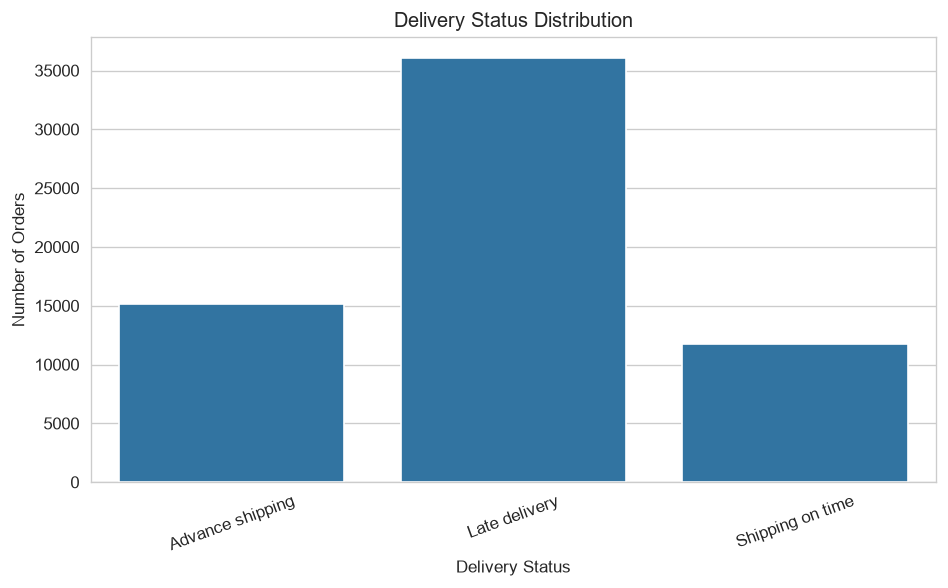

In [44]:
plt.figure(figsize=(8, 5))

sns.countplot(data=orders, x='Delivery_Status')

plt.title('Delivery Status Distribution')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig('../charts/delivery_status.png', dpi=300)
plt.show()

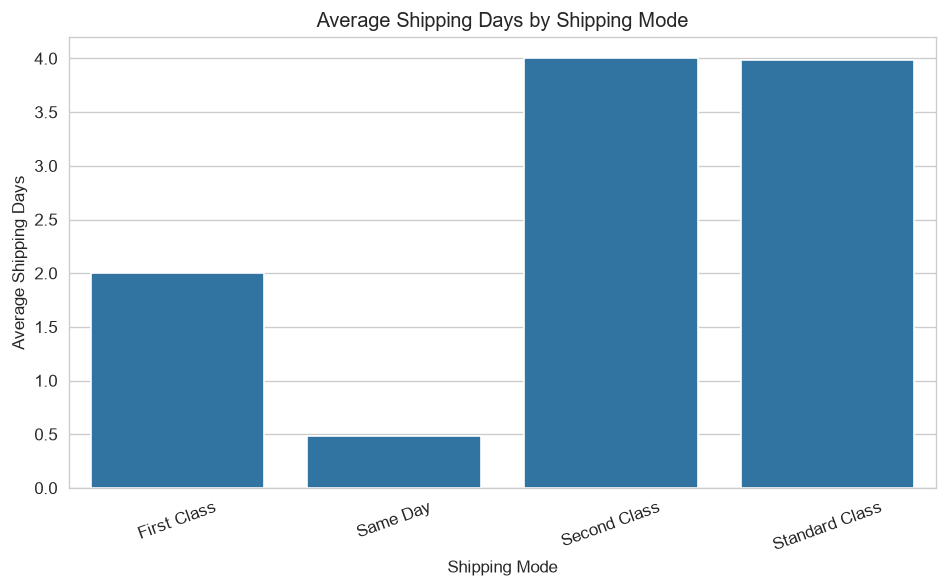

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=shipping_analysis.reset_index(),
    x='Shipping_Mode',
    y='Average_Shipping_Days'
)

plt.title('Average Shipping Days by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Shipping Days')
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig('../charts/shipping_mode_performance.png', dpi=300)
plt.show()

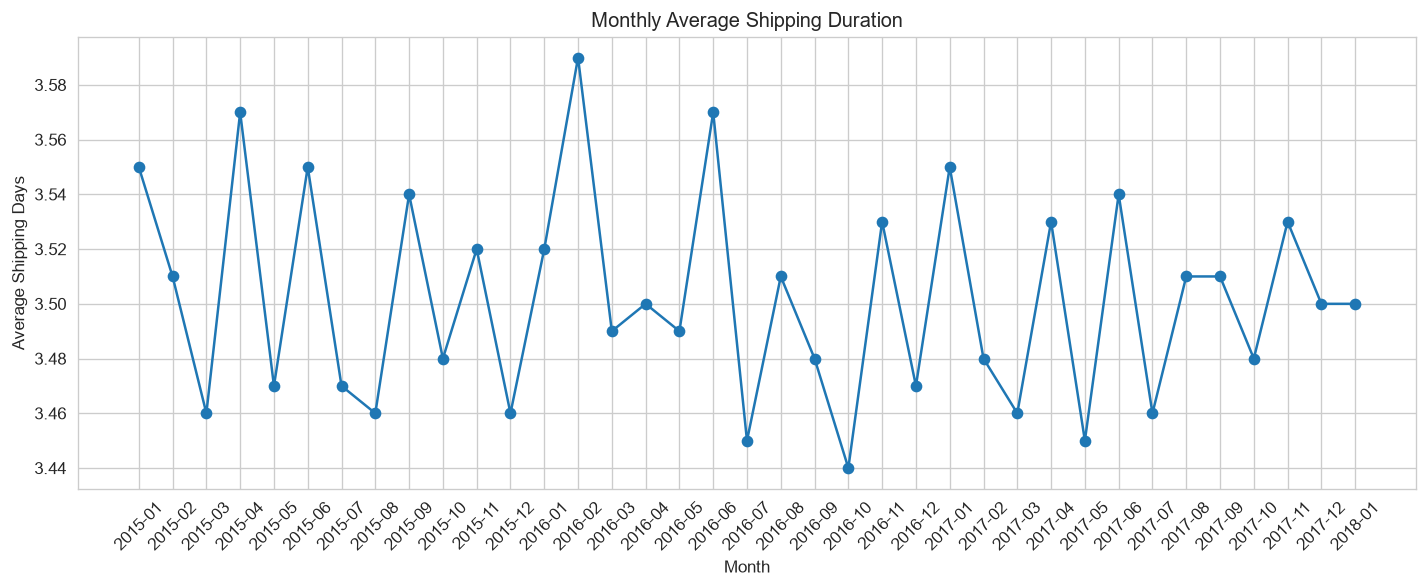

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['Average_Shipping_Days'],
    marker='o'
)

plt.title('Monthly Average Shipping Duration')
plt.xlabel('Month')
plt.ylabel('Average Shipping Days')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../charts/monthly_shipping_trend.png', dpi=300)
plt.show()

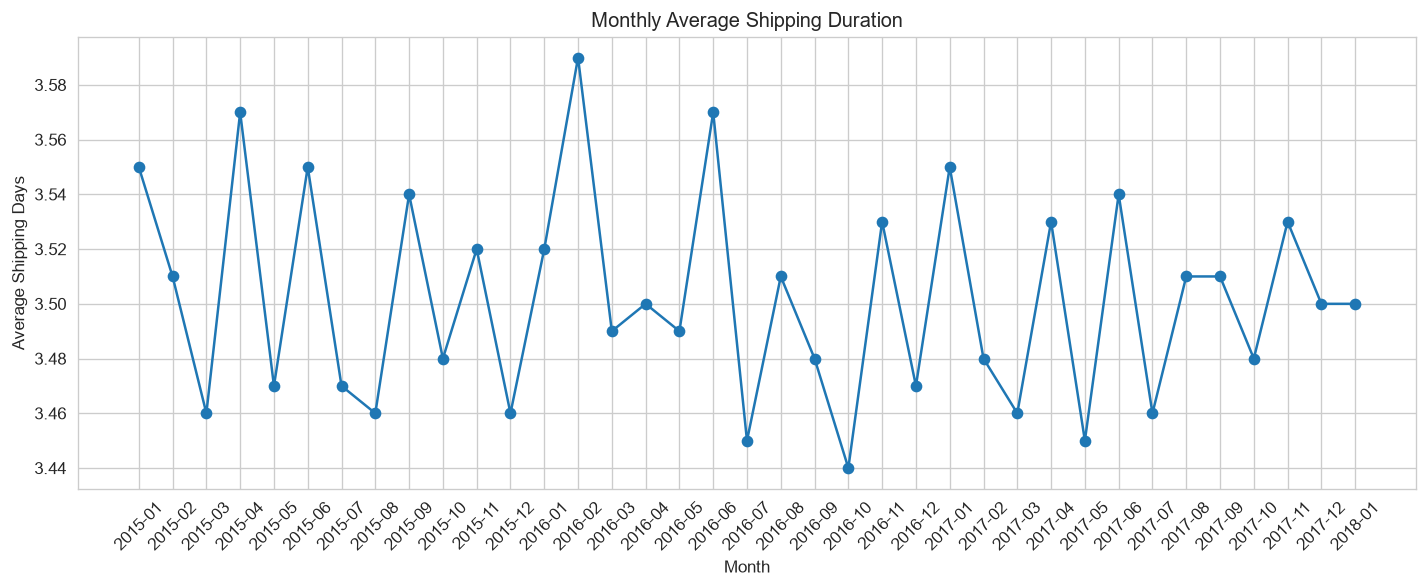

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['Average_Shipping_Days'],
    marker='o'
)

plt.title('Monthly Average Shipping Duration')
plt.xlabel('Month')
plt.ylabel('Average Shipping Days')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../charts/monthly_shipping_trend.png', dpi=300)
plt.show()

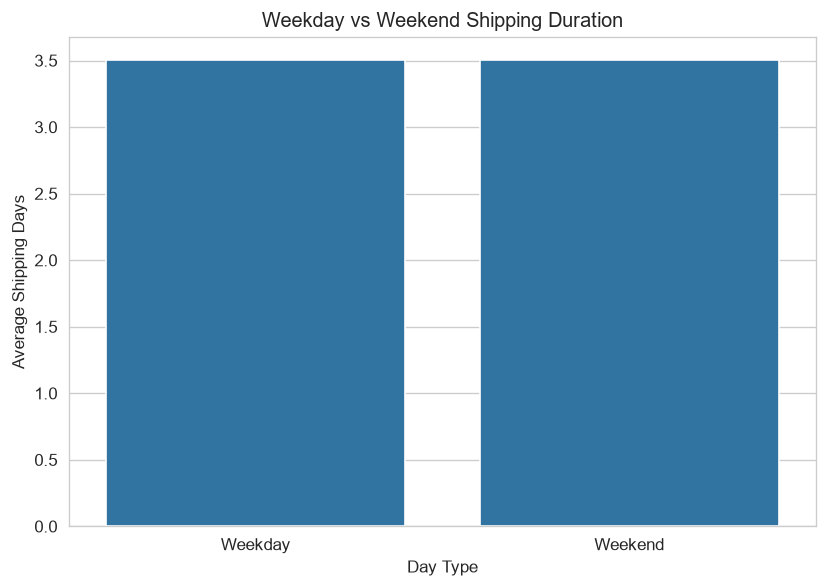

In [48]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=day_analysis.reset_index(),
    x='Day_Type',
    y='Average_Shipping_Days'
)

plt.title('Weekday vs Weekend Shipping Duration')
plt.xlabel('Day Type')
plt.ylabel('Average Shipping Days')

plt.tight_layout()
plt.savefig('../charts/weekday_weekend.png', dpi=300)
plt.show()

In [49]:
region_analysis = orders.groupby('Order_Region').agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum())
)

region_analysis['Delay_Percentage'] = (
    region_analysis['Delayed_Orders'] / region_analysis['Total_Orders'] * 100
)

region_analysis = region_analysis.round(2)

region_analysis.sort_values('Delay_Percentage', ascending=False)

,Total_Orders,Average_Shipping_Days,Delayed_Orders,Delay_Percentage
Order_Region,,,,
Central Africa,533,3.54,320,60.04
East Africa,589,3.49,348,59.08
South of USA,1280,3.51,753,58.83
West Asia,1935,3.49,1132,58.50
Western Europe,9563,3.52,5585,58.40
Eastern Europe,1246,3.52,723,58.03
Southeast Asia,4173,3.53,2421,58.02
South Asia,3219,3.49,1865,57.94
US Center,1852,3.47,1071,57.83


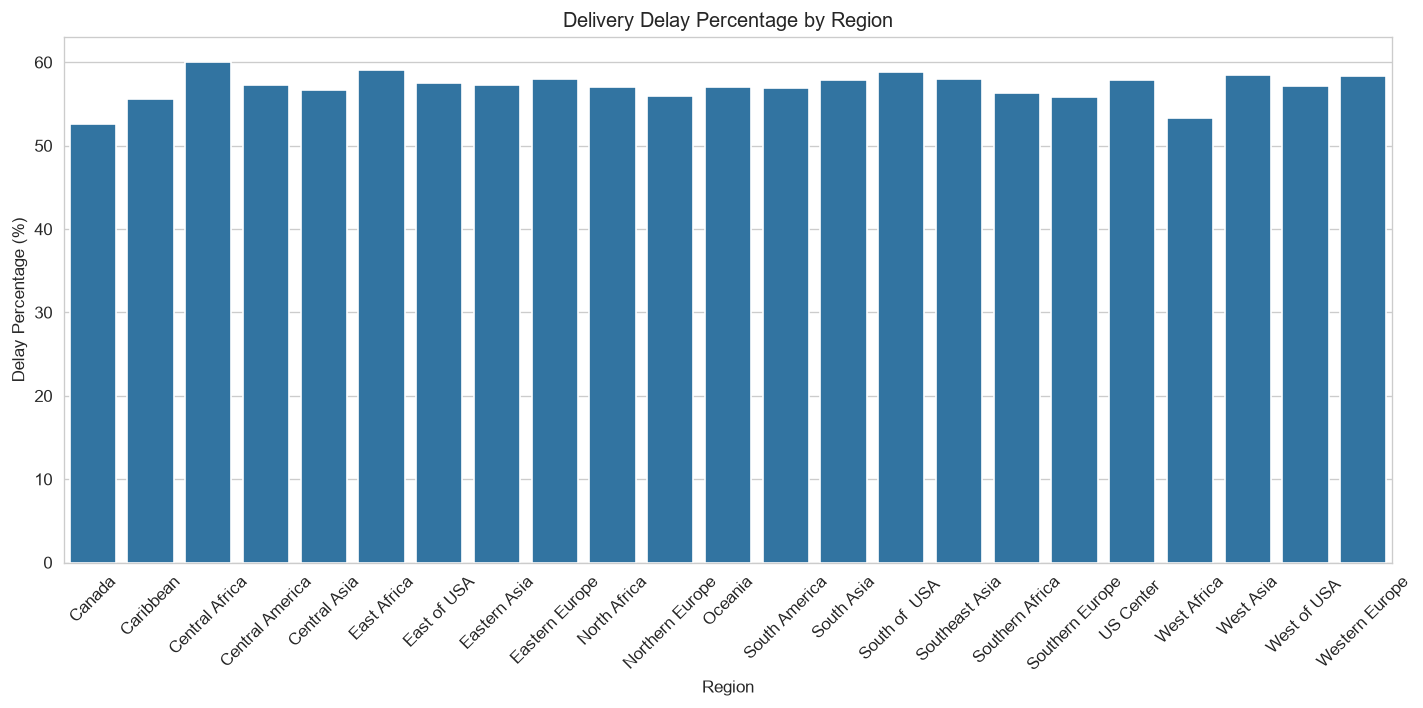

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=region_analysis.reset_index(),
    x='Order_Region',
    y='Delay_Percentage'
)

plt.title('Delivery Delay Percentage by Region')
plt.xlabel('Region')
plt.ylabel('Delay Percentage (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../charts/regional_delay.png', dpi=300)
plt.show()

In [52]:
state_analysis = orders.groupby('Order_State').agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum())
)

state_analysis['Delay_Percentage'] = (
    state_analysis['Delayed_Orders'] / state_analysis['Total_Orders'] * 100
)

state_analysis = state_analysis.round(2)

state_analysis.sort_values('Delay_Percentage', ascending=False).head(10)

,Total_Orders,Average_Shipping_Days,Delayed_Orders,Delay_Percentage
Order_State,,,,
Afyonkarahisar,3,5.67,3,100.0
Ústí nad Labem,4,4.00,4,100.0
Çanakkale,3,4.67,3,100.0
ilina,2,3.00,2,100.0
Al Hudayda,3,2.00,3,100.0
Al Marqab,1,6.00,1,100.0
Yevrey,1,1.00,1,100.0
Yalova,2,2.50,2,100.0
Zagrebacka,1,2.00,1,100.0


In [53]:
orders['Season'] = np.where(
    orders['Month'].isin(['November', 'December']),
    'Peak Season',
    'Regular Season'
)

In [54]:
season_analysis = orders.groupby('Season').agg(
    Total_Orders=('Order_ID', 'count'),
    Average_Shipping_Days=('Actual_Shipping_Days', 'mean'),
    Delayed_Orders=('Delivery_Status', lambda x: (x == 'Late delivery').sum())
)

season_analysis['Delay_Percentage'] = (
    season_analysis['Delayed_Orders'] / season_analysis['Total_Orders'] * 100
)

season_analysis.round(2)

,Total_Orders,Average_Shipping_Days,Delayed_Orders,Delay_Percentage
Season,,,,
Peak Season,10705,3.5,6158,57.52
Regular Season,52192,3.5,29890,57.27


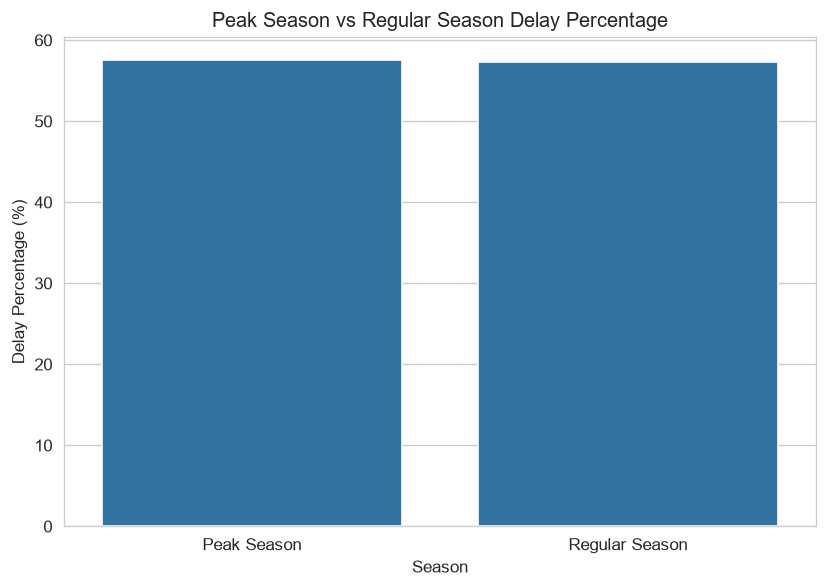

In [55]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=season_analysis.reset_index(),
    x='Season',
    y='Delay_Percentage'
)

plt.title('Peak Season vs Regular Season Delay Percentage')
plt.xlabel('Season')
plt.ylabel('Delay Percentage (%)')

plt.tight_layout()
plt.savefig('../charts/season_comparison.png', dpi=300)
plt.show()

In [56]:
risk_analysis = orders['Late_Delivery_Risk'].value_counts()

risk_analysis

Late_Delivery_Risk
1    36048
0    26849
Name: count, dtype: int64

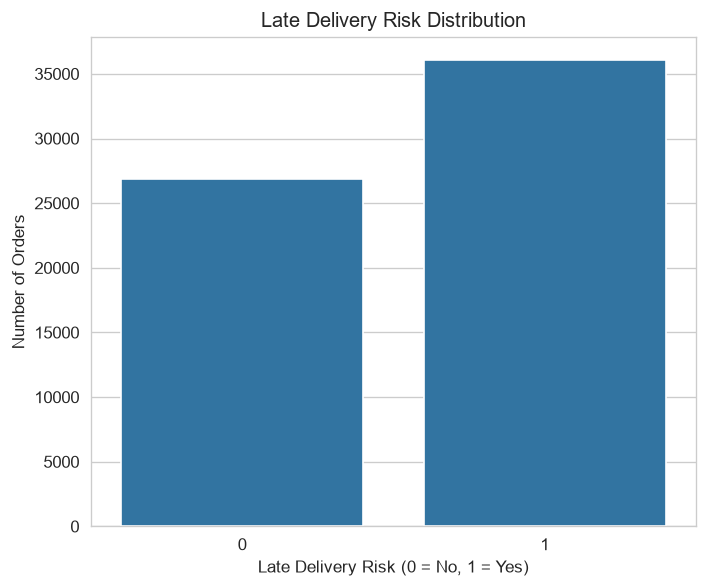

In [57]:
plt.figure(figsize=(6, 5))

sns.countplot(data=orders, x='Late_Delivery_Risk')

plt.title('Late Delivery Risk Distribution')
plt.xlabel('Late Delivery Risk (0 = No, 1 = Yes)')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.savefig('../charts/late_delivery_risk.png', dpi=300)
plt.show()

In [58]:
print("Total orders:", len(orders))

print(
    "On-time or early:",
    on_time_orders
)

print(
    "Delayed:",
    delayed_orders
)

print(
    "Total categorized:",
    on_time_orders + delayed_orders
)

Total orders: 62897
On-time or early: 26849
Delayed: 36048
Total categorized: 62897


In [59]:
print("Unique orders:", orders['Order_ID'].nunique())
print("Rows in orders dataset:", len(orders))

Unique orders: 62897
Rows in orders dataset: 62897


In [60]:
orders.to_csv('../data/processed_orders.csv', index=False)

In [61]:
kpi_summary.to_csv('../charts/kpi_summary.csv', index=False)

shipping_analysis.to_csv('../charts/shipping_analysis.csv')

monthly_analysis.to_csv('../charts/monthly_analysis.csv')

day_analysis.to_csv('../charts/day_analysis.csv')

region_analysis.to_csv('../charts/region_analysis.csv')

state_analysis.to_csv('../charts/state_analysis.csv')

season_analysis.to_csv('../charts/season_analysis.csv')